# 03 — Multi-Model Comparison Under One Identical Protocol
**P03: Hotel-Booking Cancellations and the Overbooking Decision**  
*Phase C — Checkpoint 2 (Unit VI)*

### Objectives:
Evaluate five distinct model families under a rigorous, identical protocol:
1. **Logistic Regression**: Interpretable linear baseline with L2 regularization.
2. **K-Nearest Neighbours (KNN)**: Non-parametric instance-based classifier. We illustrate why feature scaling is indispensable (preventing `lead_time` from dwarfing one-hot binaries).
3. **Single Decision Tree**: Tuned over `max_depth` via 5-fold cross-validation to balance bias and variance.
4. **Random Forest**: Bagged ensemble of 100 decorrelated trees reducing variance.
5. **HistGradientBoosting**: Fast, gradient-boosted decision tree ensemble building sequential residual estimators.

**Strict Protocol Guardrails:**
- All models share the identical `ColumnTransformer` feature pipeline.
- Hyperparameter selection and model comparison are conducted strictly via **5-fold Stratified Cross-Validation on the training set**.
- The test set is withheld and evaluated once at the conclusion.

In [1]:
import sys
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, average_precision_score

# Ensure local src modules can be imported
sys.path.insert(0, "..")
from src.data import load_raw_data, clean_data
from src.features import get_train_test_split, build_preprocessor

sns.set_theme(style="whitegrid", palette="tab10")

## 1. Load Data & Prepare Stratified Splits

In [2]:
data_path = Path("../data/raw/hotel_bookings.csv") if Path("../data/raw/hotel_bookings.csv").exists() else Path("/content/hotel_bookings.csv")
df_raw = load_raw_data(str(data_path))
df_clean = clean_data(df_raw, drop_leakage=True)

X_train, X_test, y_train, y_test = get_train_test_split(df_clean, test_size=0.2, random_state=42)
print(f"X_train shape: {X_train.shape}, y_train rate: {y_train.mean():.4f}")
print(f"X_test shape:  {X_test.shape}, y_test rate:  {y_test.mean():.4f}")

X_train shape: (95366, 28), y_train rate: 0.3708
X_test shape:  (23842, 28), y_test rate:  0.3708


## 2. Why Scaling Matters for Distance-Based Models (KNN)

In our feature matrix, `lead_time` ranges from 0 to 737 days, whereas one-hot encoded flags range from 0 to 1. In Euclidean space:
$$d(x_i, x_j) = \sqrt{(lead\_time_i - lead\_time_j)^2 + (is\_repeated_i - is\_repeated_j)^2 + \dots}$$
Without `StandardScaler`, a 30-day difference in `lead_time` contributes $30^2 = 900$ to the squared Euclidean distance, completely obliterating binary flags (max contribution $1^2 = 1$). Standard scaling centers all continuous features to unit variance, allowing binary signals and continuous durations to carry balanced geometric weight.

## 3. Hyperparameter Tuning: Decision Tree Depth
We use 5-fold cross-validation on `X_train` to select the optimal tree depth, penalizing underfitting at low depths and overfitting at high depths.

Best Decision Tree max_depth: 15 (Mean CV ROC-AUC: 0.9160)


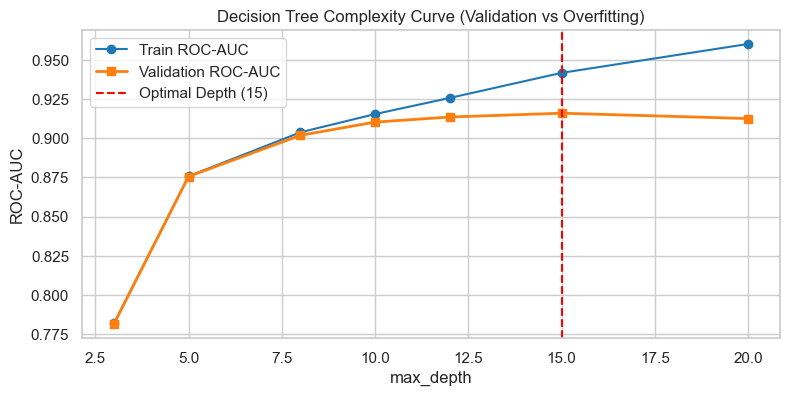

In [3]:
tree_pipe = Pipeline([
    ("preprocessor", build_preprocessor()),
    ("classifier", DecisionTreeClassifier(min_samples_leaf=10, random_state=42))
])

param_grid = {"classifier__max_depth": [3, 5, 8, 10, 12, 15, 20]}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid_search = GridSearchCV(tree_pipe, param_grid, cv=cv, scoring="roc_auc", n_jobs=-1, return_train_score=True)
grid_search.fit(X_train, y_train)

cv_results = pd.DataFrame(grid_search.cv_results_)
best_depth = grid_search.best_params_["classifier__max_depth"]
print(f"Best Decision Tree max_depth: {best_depth} (Mean CV ROC-AUC: {grid_search.best_score_:.4f})")

plt.figure(figsize=(9, 4))
plt.plot(cv_results["param_classifier__max_depth"], cv_results["mean_train_score"], marker="o", label="Train ROC-AUC")
plt.plot(cv_results["param_classifier__max_depth"], cv_results["mean_test_score"], marker="s", lw=2, label="Validation ROC-AUC")
plt.axvline(best_depth, color="red", linestyle="--", label=f"Optimal Depth ({best_depth})")
plt.title("Decision Tree Complexity Curve (Validation vs Overfitting)")
plt.xlabel("max_depth")
plt.ylabel("ROC-AUC")
plt.legend()
plt.show()

## 4. Assemble the Five Model Pipelines Under One Protocol

In [4]:
pipelines = {
    "Logistic Regression": Pipeline([
        ("preprocessor", build_preprocessor()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=42))
    ]),
    "K-Nearest Neighbours": Pipeline([
        ("preprocessor", build_preprocessor()),
        ("classifier", KNeighborsClassifier(n_neighbors=5, n_jobs=-1))
    ]),
    "Decision Tree": Pipeline([
        ("preprocessor", build_preprocessor()),
        ("classifier", DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=10, random_state=42))
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", build_preprocessor()),
        ("classifier", RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_leaf=5, n_jobs=-1, random_state=42))
    ]),
    "HistGradientBoosting": Pipeline([
        ("preprocessor", build_preprocessor()),
        ("classifier", HistGradientBoostingClassifier(max_iter=100, learning_rate=0.1, max_depth=12, random_state=42))
    ])
}

## 5. Cross-Validation on Training Set (5-Fold Stratified)

In [5]:
cv_records = []
cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for name, pipe in pipelines.items():
    auc_scores = cross_val_score(pipe, X_train, y_train, cv=cv_folds, scoring="roc_auc", n_jobs=-1)
    acc_scores = cross_val_score(pipe, X_train, y_train, cv=cv_folds, scoring="accuracy", n_jobs=-1)
    cv_records.append({
        "Model": name,
        "CV_Mean_ROC_AUC": round(auc_scores.mean(), 4),
        "CV_Std_ROC_AUC": round(auc_scores.std(), 4),
        "CV_Mean_Accuracy": round(acc_scores.mean(), 4),
        "CV_Std_Accuracy": round(acc_scores.std(), 4)
    })

cv_summary_df = pd.DataFrame(cv_records).sort_values(by="CV_Mean_ROC_AUC", ascending=False)
print("=" * 65)
print(" 5-FOLD STRATIFIED CROSS-VALIDATION SUMMARY (TRAINING SET ONLY) ")
print("=" * 65)
print(cv_summary_df.to_string(index=False))

 5-FOLD STRATIFIED CROSS-VALIDATION SUMMARY (TRAINING SET ONLY) 
               Model  CV_Mean_ROC_AUC  CV_Std_ROC_AUC  CV_Mean_Accuracy  CV_Std_Accuracy
HistGradientBoosting           0.9314          0.0013            0.8552           0.0019
       Random Forest           0.9279          0.0017            0.8501           0.0015
       Decision Tree           0.9160          0.0022            0.8417           0.0031
K-Nearest Neighbours           0.8908          0.0020            0.8266           0.0013
 Logistic Regression           0.8859          0.0015            0.8083           0.0007


## 6. Fit All Five Models on Full Training Set
With cross-validation completed, each pipeline is fit once to the full 80% training set in preparation for Phase D test-set evaluation.

In [6]:
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f"[✓] Fitted {name} on {len(X_train):,} training records.")

print("\nAll 5 models successfully trained under the shared protocol. Tag checkpoint-2.")

[✓] Fitted Logistic Regression on 95,366 training records.
[✓] Fitted K-Nearest Neighbours on 95,366 training records.
[✓] Fitted Decision Tree on 95,366 training records.
[✓] Fitted Random Forest on 95,366 training records.
[✓] Fitted HistGradientBoosting on 95,366 training records.

All 5 models successfully trained under the shared protocol. Tag checkpoint-2.
